<a href="https://colab.research.google.com/github/Faisaleka21/Data_Science26/blob/main/Tugas_praktikum_DENGAN_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
# 1. program 1, dengan EDA

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [17]:
# 1 baca dataset
df = pd.read_csv('https://raw.githubusercontent.com/Faisaleka21/Data_Science26/refs/heads/main/Data_Set/train.csv')

df = df[["Pclass", "Sex", "Age" , "Survived"]]

In [18]:
# 2 split data
train, test = train_test_split(
    df, test_size=0.2,
    random_state=42,
    stratify=df["Survived"]
)

Jumlah data: 712

Data kosong:
Pclass      0
Sex         0
Age         0
Survived    0
dtype: int64


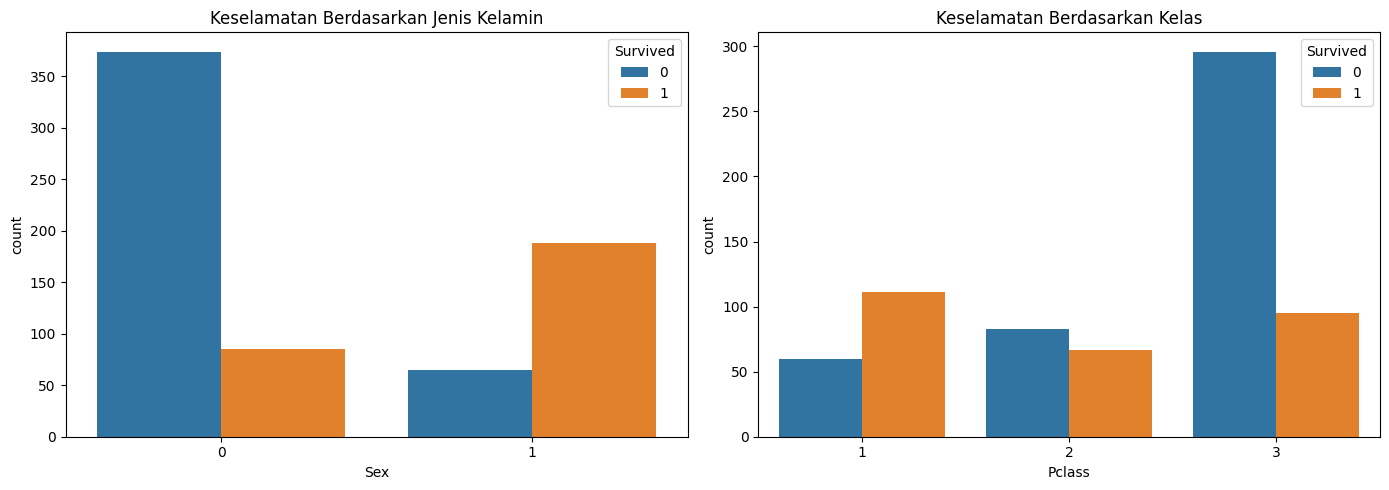


Persentase selamat berdasarkan jenis kelamin:
Sex
0    18.518519
1    74.308300
Name: Survived, dtype: float64


In [26]:
# 3. EDA pada data training
print("Jumlah data:", len(train))
print("\nData kosong:")
print(train.isnull().sum())

# Membuat figure dengan 1 baris dan 2 kolom (posisi kiri & kanan)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik 1 (Di sebelah Kiri)
sns.countplot(data=train, x="Sex", hue="Survived", ax=axes[0])
axes[0].set_title("Keselamatan Berdasarkan Jenis Kelamin")

# Grafik 2 (Di sebelah Kanan)
sns.countplot(data=train, x="Pclass", hue="Survived", ax=axes[1])
axes[1].set_title("Keselamatan Berdasarkan Kelas")

# Merapikan layout agar tidak tumpang tindih
plt.tight_layout()
plt.show()

print("\nPersentase selamat berdasarkan jenis kelamin:")
print(train.groupby("Sex")["Survived"].mean() * 100)

In [20]:
# 4 preprocessing
def proses(data) :
  data = data.copy()
  data ["Age"] = data["Age"].fillna(
      train["Age"].median()
  )
  data["Sex"] = data["Sex"].map({
      "male": 0, "female": 1
  })
  return data

train = proses(train)
test  = proses(test)

fitur = ["Pclass", "Sex", "Age"]

In [21]:
# 5. training
model = DecisionTreeClassifier(
    max_depth=3, random_state=42
)
model.fit(train[fitur], train["Survived"])

DecisionTreeClassifier(max_depth=3, random_state=42)

In [22]:
# 6. Evaluasi
prediksi = model.predict(test[fitur])

print("\nAkurasi dengan EDA:",
      accuracy_score(test["Survived"], prediksi))


Akurasi dengan EDA: 0.7653631284916201


Analisis 1:
1. Jalankan program diatas, kemudian capture semua hasilnya.
2. Amati hasil grafik jawaban no 1. Menurut Anda, apakah jenis kelamin dan kelas tiket berkaitan
dengan peluang keselamatan? Jelaskan jawaban Anda

Jawaban

1.

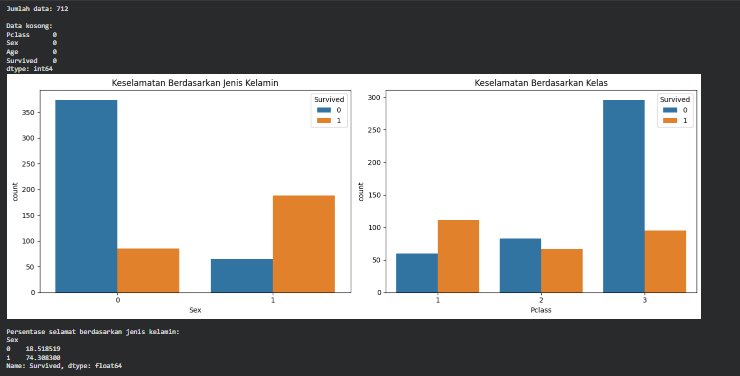

2.iya sangat berkaitan.

untuk grafik keselamatan berdasarkan jenis kelamin, untuk sex 0 = menadakan bahwa grafik warna biru lebih banyak dibandingkan warna oranye yang artinya bahwa di sex = 0 grafik biru banyak yang tidak selamat dibandingkan grafik oranye

sedangkan yng sex 1 . menandakan bahwa jumlah oranye paling banyak selamat dari pada grafik warna biru.

dan untuk keselematan berdasarkan kelas
misal pclass 1 tingkatannya paling tinggi, pclass 2 medium, pclass 3 rendah, jadi di dasarkan pada kelas ini terlihat bawha di class 3 ini lebih banyak yang tidak selamat.